# GCS Operations: Consistency Tests and New Update Rules

This notebook demonstrates:
1. **Consistency**: evolving a GCS with per-branch ICs equal to a single Gaussian IC reproduces the original result
2. **Chaining**: evolving → applying operations → evolving again (works exactly for the General ODE solver)
3. **Conditional Displacement**: qubit-conditional phase-space displacement
4. **Gaussian Operation**: symplectic transformation (squeezing, rotation, etc.)
5. **Mathematica replication**: the `Claude_GCS.nb` example in Python

In [1]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import sys, os
sys.path.append(os.path.abspath('../src'))

from Objects import Quantum_State, Hamiltonian, Symplectic
import Operations
import Gaussian

---
## 1. Consistency: single Gaussian IC vs. per-branch GCS IC

When all per-branch ICs are identical, the new per-branch path must reproduce the original single-IC result exactly.

### 1a. Force Hamiltonian (closed-form)

In [2]:
N_qubits = 1; n_modes = 1; N2 = 2**N_qubits

H_m  = np.array([[1.0, 0], [0, 1.0]])
r_m  = np.zeros((2, 1))
r_q  = np.array([[0.5], [0.0]])    # qubit-dependent force
H_q_0 = np.zeros(1)

r_0 = np.zeros((2, 1))
sigma_0 = np.eye(2)
rho_q_0 = np.array([[1, 1], [1, 1]]) / 2
t_array = np.linspace(0.01, 5.0, 100)

# --- Old method: single Gaussian IC ---
H = Hamiltonian(N_qubits, n_modes)
H.Initialize_Constant_Hamiltonians([H_m], [r_m, r_q], H_q_0)

state_old = Quantum_State(N_qubits, n_modes)
state_old.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)
state_old.Unitary_Dynamics_Numerical(H, t_array)

# --- New method: per-branch GCS IC (all identical) ---
sigma_JK_0 = np.tile(sigma_0, (N2, N2, 1, 1)).astype(complex)
r_JK_0     = np.tile(r_0,     (N2, N2, 1, 1)).astype(complex)

state_new = Quantum_State(N_qubits, n_modes)
state_new.Initialize_GCS(sigma_JK_0, r_JK_0, rho_q_0)
state_new.Unitary_Dynamics_Numerical(H, t_array)

print('Force case — max absolute difference:')
print('  sigma_JK[0,0]:', np.max(np.abs(state_new.sigma_JK_t[:,0,0] - state_old.sigma_JK_t[:,0,0])))
print('  r_JK[0,0]:    ', np.max(np.abs(state_new.r_JK_t[:,0,0]     - state_old.r_JK_t[:,0,0])))
print('  C_JK[0,1]:    ', np.max(np.abs(state_new.C_JK_t[:,0,1]     - state_old.C_JK_t[:,0,1])))
print('  phi_JK[0,1]:  ', np.max(np.abs(state_new.phi_JK_t[:,0,1]   - state_old.phi_JK_t[:,0,1])))
print('  rho_q[0,1]:   ', np.max(np.abs(state_new.rho_q_t[:,0,1]    - state_old.rho_q_t[:,0,1])))

This is a time independent operator-valued force Hamiltonian
Initializing a Gaussian State
Initializing a GCS
Force case — max absolute difference:
  sigma_JK[0,0]: 0.0
  r_JK[0,0]:     0.0
  C_JK[0,1]:     0.0
  phi_JK[0,1]:   0.0
  rho_q[0,1]:    0.0


### 1b. General Hamiltonian (ODE solver)

In [3]:
# General case: qubit-dependent Hamiltonian H_J = H_0 + J*H_1
# H_0 = omega * I2, H_1 = g * diag(1, -1)
omega = 1.0; g_coup = 0.3
H_0 = omega * np.eye(2)
H_1 = g_coup * np.diag([1., -1.])
r_m_g = np.zeros((2, 1)); r_q_g = np.zeros((2, 1))
H_q_0_g = np.zeros(1)   # N_qubits=1 -> 1 element

H_gen = Hamiltonian(N_qubits, n_modes)
H_gen.Initialize_Constant_Hamiltonians([H_0, H_1], [r_m_g, r_q_g], H_q_0_g)

state_gen_old = Quantum_State(N_qubits, n_modes)
state_gen_old.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)
state_gen_old.Unitary_Dynamics_Numerical(H_gen, t_array)

state_gen_new = Quantum_State(N_qubits, n_modes)
state_gen_new.Initialize_GCS(sigma_JK_0, r_JK_0, rho_q_0)
state_gen_new.Unitary_Dynamics_Numerical(H_gen, t_array)

print('General case — max absolute difference:')
print('  sigma_JK[0,0]:', np.max(np.abs(state_gen_new.sigma_JK_t[:,0,0] - state_gen_old.sigma_JK_t[:,0,0])))
print('  r_JK[0,0]:    ', np.max(np.abs(state_gen_new.r_JK_t[:,0,0]     - state_gen_old.r_JK_t[:,0,0])))
print('  C_JK[0,1]:    ', np.max(np.abs(state_gen_new.C_JK_t[:,0,1]     - state_gen_old.C_JK_t[:,0,1])))
print('  phi_JK[0,1]:  ', np.max(np.abs(state_gen_new.phi_JK_t[:,0,1]   - state_gen_old.phi_JK_t[:,0,1])))
print('  rho_q[0,1]:   ', np.max(np.abs(state_gen_new.rho_q_t[:,0,1]    - state_gen_old.rho_q_t[:,0,1])))

This is a time independent operator-valued general Hamiltonian
Initializing a Gaussian State
Initializing a GCS
General case — max absolute difference:
  sigma_JK[0,0]: 0.0
  r_JK[0,0]:     0.0
  C_JK[0,1]:     0.0
  phi_JK[0,1]:   0.0
  rho_q[0,1]:    0.0


---
## 2. Chaining: evolve → re-initialise from last state → evolve again

For the **General (ODE) case**, the chain must be exact: 
evolving [0, t1] then [t1, t2] from the endpoint should match a single evolution [0, t2].

> **Note**: For the Force (closed-form) case, the decoherence formula C_JK is defined relative to t=0 and is not additively composable across segments, so chaining is exact only for σ and r but not for C/φ. Use the General case for chaining.

Initializing a Gaussian State
This is a time independent operator-valued general Hamiltonian
Initializing a GCS
This is a time independent operator-valued general Hamiltonian
Initializing a Gaussian State
This is a time independent operator-valued general Hamiltonian
Chaining errors (General case, ODE tolerance ~1e-3):
  rho_q[0,1]:              2.58e-04  (direct comparison)
  C_total (s1[-1]+s2):     5.39e-04  (summed increments)
  phi (incremental, at t=5): 7.22e-16


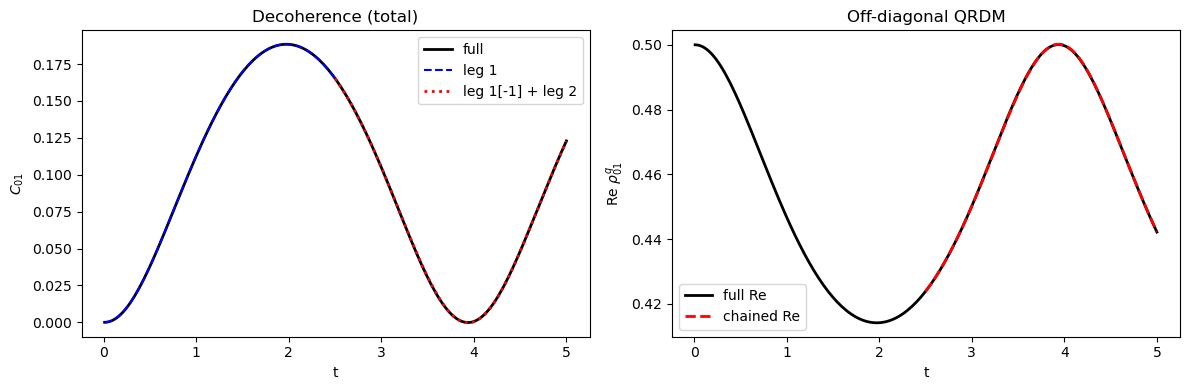

In [4]:
t1 = np.linspace(0.01, 2.5, 100)
t2 = np.linspace(2.5, 5.0, 100)
t_full = np.concatenate([t1, t2[1:]])   # 199 time points

def make_H_gen():
    H = Hamiltonian(N_qubits, n_modes)
    H.Initialize_Constant_Hamiltonians([H_0, H_1], [r_m_g, r_q_g], H_q_0_g)
    return H

# Leg 1: evolve from t=0 to t=2.5
s1 = Quantum_State(N_qubits, n_modes)
s1.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)
s1.Unitary_Dynamics_Numerical(make_H_gen(), t1)

# Leg 2: re-initialise from the last GCS snapshot, then evolve t=2.5 to 5.0
s2 = Quantum_State(N_qubits, n_modes)
s2.Initialize_GCS(s1.sigma_JK_t[-1], s1.r_JK_t[-1], s1.rho_q_t[-1])
s2.Unitary_Dynamics_Numerical(make_H_gen(), t2)

# Full reference: single evolution from t=0 to t=5.0
sf = Quantum_State(N_qubits, n_modes)
sf.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)
sf.Unitary_Dynamics_Numerical(make_H_gen(), t_full)

n1 = len(t1)

# rho_q_t carries the total accumulated decoherence and phase: compare directly.
# C_JK_t from each leg is *incremental* (starts at 0 for each leg),
# so total C = s1.C[-1] + s2.C (the partial sums match sf.C[n1-1:]).
rho_diff = np.max(np.abs(s2.rho_q_t[:,0,1]  - sf.rho_q_t[n1-1:,0,1]))
C_total_chained = np.real(s2.C_JK_t[:,0,1] + s1.C_JK_t[-1,0,1])
C_diff = np.max(np.abs(C_total_chained - np.real(sf.C_JK_t[n1-1:,0,1])))

print('Chaining errors (General case, ODE tolerance ~1e-3):')
print(f'  rho_q[0,1]:              {rho_diff:.2e}  (direct comparison)')
print(f'  C_total (s1[-1]+s2):     {C_diff:.2e}  (summed increments)')
print(f'  phi (incremental, at t=5): {np.abs(s2.phi_JK_t[-1,0,1] + s1.phi_JK_t[-1,0,1] - sf.phi_JK_t[-1,0,1]):.2e}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# C_total comparison
axes[0].plot(t_full, np.real(sf.C_JK_t[:,0,1]), 'k-', lw=2, label='full')
axes[0].plot(t1, np.real(s1.C_JK_t[:,0,1]), 'b--', lw=1.5, label='leg 1')
axes[0].plot(t2, C_total_chained, 'r:', lw=2, label='leg 1[-1] + leg 2')
axes[0].set_xlabel('t'); axes[0].set_ylabel(r'$C_{01}$')
axes[0].legend(); axes[0].set_title('Decoherence (total)')

# rho_q comparison
axes[1].plot(t_full, np.real(sf.rho_q_t[:,0,1]), 'k-', lw=2, label='full Re')
axes[1].plot(t2, np.real(s2.rho_q_t[:,0,1]), 'r--', lw=2, label='chained Re')
axes[1].set_xlabel('t'); axes[1].set_ylabel(r'Re $\rho^q_{01}$')
axes[1].legend(); axes[1].set_title(r'Off-diagonal QRDM')
plt.tight_layout(); plt.show()

---
## 3. Conditional Displacement

Formula (Eq. 5):
$$r_{jk} \to r_{jk} - \tfrac{1}{2}(r_j + r_k) - \tfrac{i}{2}\sigma_{jk}\Omega(r_j - r_k)$$
$$C_{jk} \to C_{jk} + \tfrac{1}{4}(r_j-r_k)^T\Omega^T\sigma_{jk}\Omega(r_j-r_k) + (r_j-r_k)^T\Omega r_{jk}^I$$
$$\phi_{jk} \to \phi_{jk} + (r_j-r_k)^T\Omega r_{jk}^R - \tfrac{1}{2}r_j^T\Omega r_k$$

In [5]:
# Simple 1-qubit, 1-mode state: ground state (sigma=I, r=0, C=0, phi=0)
N_qubits_op = 1; n_modes_op = 1; N2_op = 2
Omega = Gaussian.Omega_N(n_modes_op)

sigma_JK = np.tile(np.eye(2), (N2_op, N2_op, 1, 1)).astype(complex)
r_JK     = np.zeros((N2_op, N2_op, 2, 1), dtype=complex)

# Branch 0 (J=-1): stays at 0; branch 1 (J=+1): displaced by alpha in x
alpha = 2.0
r_array = np.array([[[0.], [0.]], [[alpha], [0.]]])

sigma_new, r_new, delta_C, delta_phi = Operations.Conditional_Displacement(
    N_qubits_op, n_modes_op, sigma_JK, r_JK, r_array)

# Manual check
diff = r_array[0] - r_array[1]   # [-alpha, 0]
r01_manual = r_JK[0,1] - 0.5*(r_array[0]+r_array[1]) - 0.5j * sigma_JK[0,1] @ Omega @ diff
dC_manual  = 0.25 * float(diff.T @ Omega.T @ np.eye(2) @ Omega @ diff)  # r_JK=0 -> Im term = 0
dphi_manual = float(diff.T @ Omega @ np.real(r_JK[0,1])) - 0.5 * float(r_array[0].T @ Omega @ r_array[1])

print(f'r_new[0,0] = {r_new[0,0].T}  (expect [[0,0]])')
print(f'r_new[1,1] = {r_new[1,1].T}  (expect [[-{alpha},0]])')
print(f'r_new[0,1] = {r_new[0,1].T}  (expect {r01_manual.T})')
print(f'match r_new[0,1]: {np.allclose(r_new[0,1], r01_manual)}')
print()
print(f'delta_C[0,1]   = {delta_C[0,1]:.6f}  (manual = {dC_manual:.6f},  = alpha^2/4 = {alpha**2/4})')
print(f'delta_phi[0,1] = {delta_phi[0,1]:.6f} (manual = {dphi_manual:.6f})')
print(f'Conjugate symmetry r_new[1,0] = conj(r_new[0,1]): {np.allclose(r_new[1,0], np.conjugate(r_new[0,1]))}')

r_new[0,0] = [[0.-0.j 0.-0.j]]  (expect [[0,0]])
r_new[1,1] = [[-2.-0.j  0.-0.j]]  (expect [[-2.0,0]])
r_new[0,1] = [[-1.+0.j  0.-1.j]]  (expect [[-1.+0.j  0.-1.j]])
match r_new[0,1]: True

delta_C[0,1]   = 1.000000  (manual = 1.000000,  = alpha^2/4 = 1.0)
delta_phi[0,1] = 0.000000 (manual = 0.000000)
Conjugate symmetry r_new[1,0] = conj(r_new[0,1]): True


/var/folders/gf/stjx7_gd7x54p6_0r6fskqbr0000gn/T/ipykernel_95332/2083073344.py:18: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  dC_manual  = 0.25 * float(diff.T @ Omega.T @ np.eye(2) @ Omega @ diff)  # r_JK=0 -> Im term = 0
/var/folders/gf/stjx7_gd7x54p6_0r6fskqbr0000gn/T/ipykernel_95332/2083073344.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  dphi_manual = float(diff.T @ Omega @ np.real(r_JK[0,1])) - 0.5 * float(r_array[0].T @ Omega @ r_array[1])


### Via Objects.Quantum_State.Apply_Conditional_Displacement

In [6]:
state_cd = Quantum_State(N_qubits_op, n_modes_op)
state_cd.Initialize_GCS(sigma_JK.copy(), r_JK.copy(), np.array([[0.5, 0.5],[0.5, 0.5]]))
state_cd.Apply_Conditional_Displacement(r_array)

print('rho_q after displacement:')
print(state_cd.rho_q_0)
# Off-diagonal should acquire exp(-delta_C[0,1]) = exp(-alpha^2/4) factor
expected_01 = 0.5 * np.exp(-alpha**2/4)
print(f'rho_q[0,1] = {state_cd.rho_q_0[0,1]:.6f}  (expected {expected_01:.6f} = 0.5 * exp(-alpha^2/4))')

Initializing a GCS
Initializing a GCS
rho_q after displacement:
[[0.5       +0.j 0.18393972+0.j]
 [0.18393972+0.j 0.5       +0.j]]
rho_q[0,1] = 0.183940+0.000000j  (expected 0.183940 = 0.5 * exp(-alpha^2/4))


---
## 4. Gaussian Operation

$$\sigma_{jk} \to \Omega X^{-1}\Omega^T \sigma_{jk} \Omega X^{-1T}\Omega^T + \Omega X^{-1} Y X^{-1T}\Omega^T$$
$$r_{jk} \to \Omega X^{-1T}\Omega^T r_{jk} + r_c, \quad C_{jk} \to C_{jk} + \ln(\det X), \quad \phi_{jk} \text{ unchanged}$$

In [7]:
# Squeezing: X = diag(sqrt(s), 1/sqrt(s)) -> det X = 1 -> C unchanged
s = 3.0
X = np.diag([np.sqrt(s), 1/np.sqrt(s)])
Y = np.zeros((2, 2))
r_c = np.zeros((2, 1))

sigma_sq, r_sq, dC_sq, dphi_sq = Operations.Gaussian_Operation(
    N_qubits_op, n_modes_op, sigma_JK, r_JK, X, Y, r_c)

X_inv = np.linalg.inv(X)
M = Omega @ X_inv @ Omega.T
sigma_exp = M @ np.eye(2) @ M.T

print('Squeezed sigma[0,0]:')
print(np.real(sigma_sq[0,0]))
print('Expected (M @ I @ M^T):')
print(sigma_exp)
print('Match:', np.allclose(sigma_sq[0,0], sigma_exp))
print(f'delta_C = ln(det X) = {dC_sq[0,0]:.6f}  (expected {np.log(np.linalg.det(X)):.6f} = 0 for unitary squeezing)')
print()

# Non-unitary amplification: X = sqrt(amp) * I -> det X = amp^n -> C += n * ln(amp)
amp = 2.0
X_amp = np.sqrt(amp) * np.eye(2)
Y_amp = (amp - 1) * np.eye(2)   # Y chosen so that sigma -> sigma (GKSL-like)
sigma_amp, r_amp, dC_amp, _ = Operations.Gaussian_Operation(
    N_qubits_op, n_modes_op, sigma_JK, r_JK, X_amp, Y_amp, r_c)
print(f'Amplification (amp={amp}): delta_C = {dC_amp[0,0]:.4f}  (expect ln({amp}) = {np.log(amp):.4f})')

Squeezed sigma[0,0]:
[[3.         0.        ]
 [0.         0.33333333]]
Expected (M @ I @ M^T):
[[3.         0.        ]
 [0.         0.33333333]]
Match: True
delta_C = ln(det X) = 0.000000  (expected 0.000000 = 0 for unitary squeezing)

Amplification (amp=2.0): delta_C = 0.6931  (expect ln(2.0) = 0.6931)


---
## 5. Mathematica `Claude_GCS.nb` Replication

**Setup** from the notebook (`Atom-Nanoparticle with Qubit`):
- 1 qubit, 2 modes, vacuum state
- **Step 1**: conditional displacement — branch $J{=}{+1}$ displaced by $\Delta x = 2$ in $x_1$
- **Step 2**: trivial squeezing ($s_1{=}s_2{=}1$, $r_c{=}0$)
- **Step 3**: evolve under coupled-oscillator Hamiltonian $H_g$ with $g=0.1$

In [8]:
N_qubits_m = 1; n_modes_m = 2; N2_m = 2**N_qubits_m
Delta_x = 2.0; g = 0.1; s1 = 1.0; s2 = 1.0

# --- Ground state ---
r0_4    = np.zeros((4, 1))
sigma0_4 = np.eye(4)
rho_q_0m = np.array([[1, 1], [1, 1]]) / 2

sigma_JK_m = np.tile(sigma0_4, (N2_m, N2_m, 1, 1)).astype(complex)
r_JK_m     = np.tile(r0_4,     (N2_m, N2_m, 1, 1)).astype(complex)

state_m = Quantum_State(N_qubits_m, n_modes_m)
state_m.Initialize_GCS(sigma_JK_m, r_JK_m, rho_q_0m)

# Step 1: conditional displacement
r_dis_m = np.array([[[0.],[0.],[0.],[0.]],[[Delta_x],[0.],[0.],[0.]]])
state_m.Apply_Conditional_Displacement(r_dis_m)

print('After conditional displacement:')
print('  r[0,0] =', state_m.r_0[0,0].T, '  (J=-1: stays at 0)')
print('  r[1,1] =', state_m.r_0[1,1].T, '  (J=+1: shifted by -Delta_x)')
print('  rho_q[0,1] =', state_m.rho_q_0[0,1], '  (= 0.5 * exp(-1) ≈', 0.5*np.exp(-1), ')')
print('  Separation |r[1,1]-r[0,0]| =', np.linalg.norm(state_m.r_0[1,1] - state_m.r_0[0,0]))

Initializing a GCS
Initializing a GCS
After conditional displacement:
  r[0,0] = [[0.-0.j 0.-0.j 0.-0.j 0.-0.j]]   (J=-1: stays at 0)
  r[1,1] = [[-2.-0.j  0.-0.j  0.-0.j  0.-0.j]]   (J=+1: shifted by -Delta_x)
  rho_q[0,1] = (0.18393972058572117+0j)   (= 0.5 * exp(-1) ≈ 0.18393972058572117 )
  Separation |r[1,1]-r[0,0]| = 2.0


In [9]:
# Step 2: trivial Gaussian operation (s1=s2=1 -> X=I, Y=0, r_c=0)
X_m = np.diag([np.sqrt(s1), 1/np.sqrt(s1), np.sqrt(s2), 1/np.sqrt(s2)])
Y_m = np.zeros((4, 4))
r_c_m = np.zeros((4, 1))
state_m.Apply_Gaussian_Operation(X_m, Y_m, r_c_m)
print('After trivial Gaussian op: r[1,1] unchanged =', state_m.r_0[1,1].T)

Initializing a GCS
After trivial Gaussian op: r[1,1] unchanged = [[-2.-0.j  0.-0.j  0.-0.j  0.-0.j]]


In [10]:
# Step 3: evolve under Hg (coupled oscillators, zero qubit-dependent force)
Hg = np.array([[1-g, 0,   g,   0],
               [0,   1,   0,   0],
               [g,   0,   1-g, 0],
               [0,   0,   0,   1]])
r_zero4 = np.zeros((4, 1))
H_q_0_m = np.zeros(1)

H_dyn_m = Hamiltonian(N_qubits_m, n_modes_m)
H_dyn_m.Initialize_Constant_Hamiltonians([Hg], [r_zero4, r_zero4], H_q_0_m)

t_m = np.linspace(0.0, 2*np.pi, 300)
state_m.Unitary_Dynamics_Numerical(H_dyn_m, t_m)

# Sanity checks
trace_t = np.real(state_m.rho_q_t[:,0,0] + state_m.rho_q_t[:,1,1])
sym_err = np.max(np.abs(state_m.sigma_JK_t[:,1,0] - np.conjugate(state_m.sigma_JK_t[:,0,1])))
print('Tr[rho_q] range: [{:.8f}, {:.8f}]  (should be 1)'.format(trace_t.min(), trace_t.max()))
print('Hermitian symmetry error (sigma_KJ - sigma_JK*):', sym_err)

This is a time independent operator-valued force Hamiltonian
Tr[rho_q] range: [1.00000000, 1.00000000]  (should be 1)
Hermitian symmetry error (sigma_KJ - sigma_JK*): 0.0


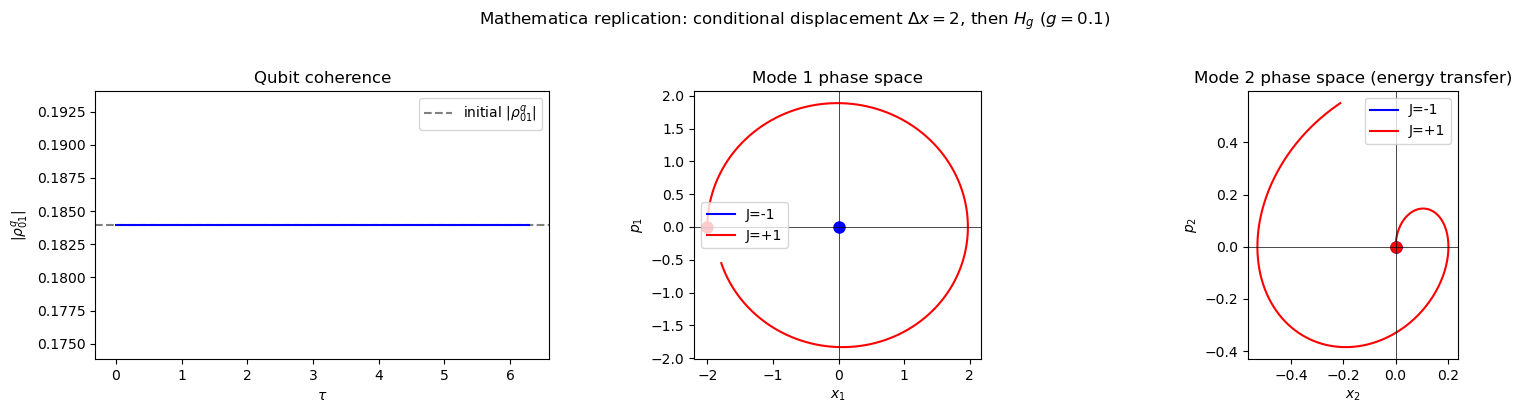

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# |rho_q[0,1]| decays from the initial exp(-1) * 0.5 = 0.184 set by the conditional displacement
axes[0].axhline(0.5*np.exp(-1), color='gray', ls='--', label=r'initial $|\rho^q_{01}|$')
axes[0].plot(t_m, np.abs(state_m.rho_q_t[:,0,1]), 'b-')
axes[0].set_xlabel(r'$\tau$'); axes[0].set_ylabel(r'$|\rho^q_{01}|$')
axes[0].set_title('Qubit coherence'); axes[0].legend()

# Phase-space trajectories for mode 1 (indices 0,1)
r00 = np.real(state_m.r_JK_t[:, 0, 0])
r11 = np.real(state_m.r_JK_t[:, 1, 1])
axes[1].plot(r00[:, 0, 0], r00[:, 1, 0], 'b-', lw=1.5, label='J=-1')
axes[1].plot(r11[:, 0, 0], r11[:, 1, 0], 'r-', lw=1.5, label='J=+1')
axes[1].plot(r00[0,0,0], r00[0,1,0], 'bo', ms=8); axes[1].plot(r11[0,0,0], r11[0,1,0], 'ro', ms=8)
axes[1].set_xlabel(r'$x_1$'); axes[1].set_ylabel(r'$p_1$')
axes[1].set_title('Mode 1 phase space'); axes[1].legend(); axes[1].set_aspect('equal')
axes[1].axhline(0,c='k',lw=.5); axes[1].axvline(0,c='k',lw=.5)

# Mode 2 trajectories
axes[2].plot(r00[:, 2, 0], r00[:, 3, 0], 'b-', lw=1.5, label='J=-1')
axes[2].plot(r11[:, 2, 0], r11[:, 3, 0], 'r-', lw=1.5, label='J=+1')
axes[2].plot(r00[0,2,0], r00[0,3,0], 'bo', ms=8); axes[2].plot(r11[0,2,0], r11[0,3,0], 'ro', ms=8)
axes[2].set_xlabel(r'$x_2$'); axes[2].set_ylabel(r'$p_2$')
axes[2].set_title('Mode 2 phase space (energy transfer)'); axes[2].legend(); axes[2].set_aspect('equal')
axes[2].axhline(0,c='k',lw=.5); axes[2].axvline(0,c='k',lw=.5)

plt.suptitle(r'Mathematica replication: conditional displacement $\Delta x=2$, then $H_g$ ($g=0.1$)', y=1.02)
plt.tight_layout(); plt.show()

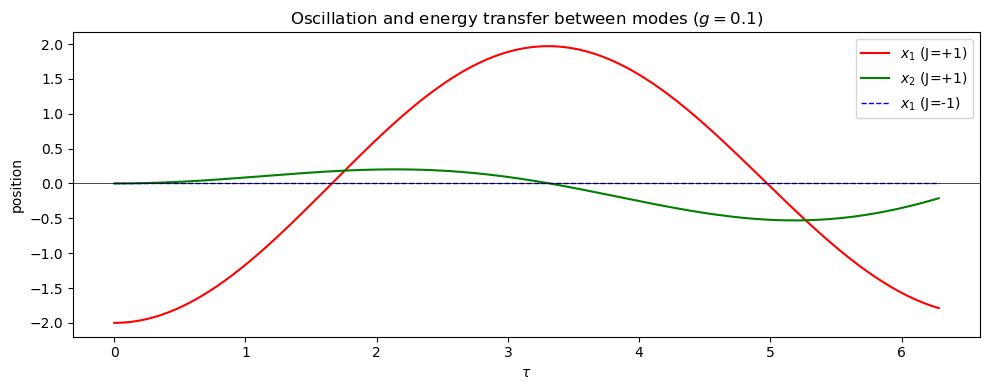

At t=pi (half period):
  r[0,0] = [[0. 0. 0. 0.]]
  r[1,1] = [[ 1.942344    0.3096842   0.05754567 -0.28867057]]


In [12]:
# Energy transfer between modes due to coupling g
# x_1(t) for J=+1 branch should oscillate with frequency ~sqrt((1-g)^2 + g^2)
x1_11 = r11[:, 0, 0]
x2_11 = r11[:, 2, 0]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t_m, x1_11, 'r-', label=r'$x_1$ (J=+1)')
ax.plot(t_m, x2_11, 'g-', label=r'$x_2$ (J=+1)')
ax.plot(t_m, r00[:,0,0], 'b--', lw=1, label=r'$x_1$ (J=-1)')
ax.set_xlabel(r'$\tau$'); ax.set_ylabel('position')
ax.set_title('Oscillation and energy transfer between modes ($g=0.1$)')
ax.legend(); ax.axhline(0, c='k', lw=.5)
plt.tight_layout(); plt.show()

print('At t=pi (half period):')
t_half = np.argmin(np.abs(t_m - np.pi))
print(f'  r[0,0] = {np.real(state_m.r_JK_t[t_half,0,0]).T}')
print(f'  r[1,1] = {np.real(state_m.r_JK_t[t_half,1,1]).T}')

In [ ]:
/